Installation and Imports

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

Load and clean the dataset

In [2]:
excel_path = "C:/Users/Benyamin/Documents/KAN/FinalDataNN.xlsx"
df = pd.read_excel(excel_path)

df_cleaned = df.dropna(subset=["P", "Y", "Ptest", "Ytest"])

P_train = df_cleaned["P"].values.astype("float32")
Y_train = df_cleaned["Y"].values.astype("float32")
P_test = df_cleaned["Ptest"].values.astype("float32")
Y_test = df_cleaned["Ytest"].values.astype("float32")

print(f"Train set size: {len(P_train)} samples")
print(f"Test set size: {len(P_test)} samples")

Train set size: 1072 samples
Test set size: 1072 samples


Hyper-parameters

In [3]:
K_S        = 3   # k: Spline order 
G_S        = 3   # g: Grid size 
IMIN       = 0.0 
IMAX       = 1.0 
Order      = 2   # order: Nonlinearization power of HR-ReLU 
Batch_Size  = 32
Context_Len = 120
Pred_Len    = 20
H_Dims      = 32
N_Epochs    = 3000
Learning_Rate = 3e-4
Seq_Step = 5
Num_Layers  = 2
Bidirectional = False

Displaying Time Series

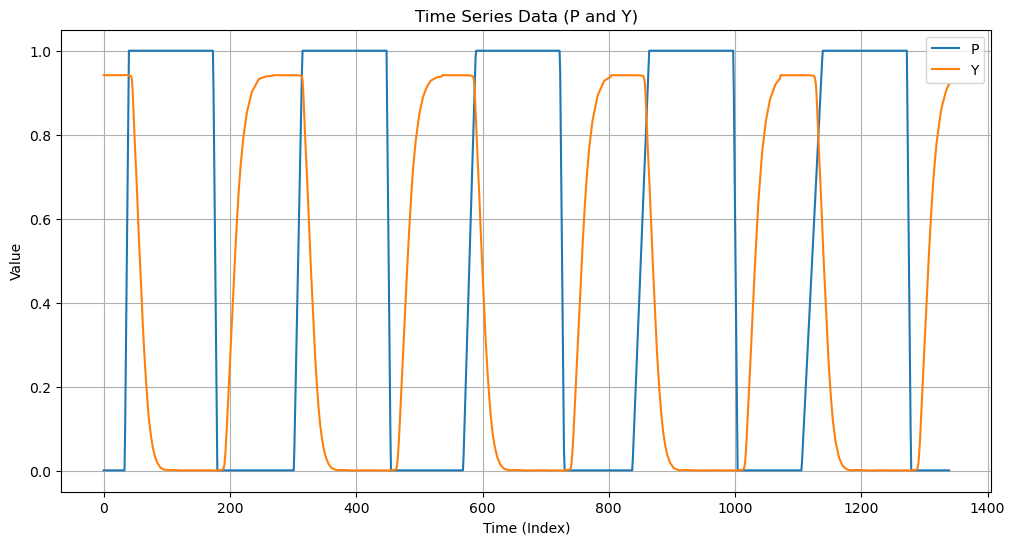

In [4]:
time_series_data_P = df["P"]
time_series_data_Y = df["Y"]

plt.figure(figsize=(12, 6))
plt.plot(time_series_data_P, label="P")
plt.plot(time_series_data_Y, label="Y")
plt.title("Time Series Data (P and Y)")
plt.xlabel("Time (Index)")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.show()

Sliding-window dataset (P → Y)

In [5]:
class PairedTimeSeriesDataset(Dataset):
    def __init__(self, x_series, y_series, context_len=Context_Len, pred_len=Pred_Len):
        self.x = torch.tensor(x_series, dtype=torch.float32)
        self.y = torch.tensor(y_series, dtype=torch.float32)
        self.context_len = context_len
        self.pred_len = pred_len
        self.total_len = context_len + pred_len
        self.n_samples = max(len(self.x) - self.total_len + 1, 0)

    def __len__(self):
        return self.n_samples

    def __getitem__(self, idx):
        x_win = self.x[idx: idx + self.context_len]
        y_win = self.y[idx + self.context_len: idx + self.total_len]
        return x_win, y_win

train_dataset = PairedTimeSeriesDataset(P_train, Y_train)
test_dataset = PairedTimeSeriesDataset(P_test, Y_test)

train_loader = DataLoader(train_dataset, batch_size=Batch_Size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=Batch_Size, shuffle=False)

print(f"Train windows: {len(train_dataset)}")
print(f"Test windows: {len(test_dataset)}")

Train windows: 933
Test windows: 933


HRKAN layer

In [6]:
class HRKANLayer(nn.Module):
    def __init__(self, input_size: int, g: int, k: int, output_size: int, imin: float, imax: float, order=1, train_ab: bool = True):
        super().__init__()
        self.g, self.k, self.r = g, k, 2 * g / ((k + 1) * (imax - imin))
        self.order = order
        self.input_size, self.output_size = input_size, output_size

        phase_low = (imax - imin) * (np.arange(-k, g) / g) - (-imin)
        phase_height = phase_low + (k + 1) / g * (imax - imin)

        self.phase_low = nn.Parameter(
            torch.tensor(np.array([phase_low for _ in range(input_size)]), dtype=torch.float32),
            requires_grad=train_ab
        )
        self.phase_height = nn.Parameter(
            torch.tensor(np.array([phase_height for _ in range(input_size)]), dtype=torch.float32),
            requires_grad=train_ab
        )
        self.equal_size_conv = nn.Conv2d(1, output_size, (g + k, input_size))

    def forward(self, x):
        x_expanded = x.unsqueeze(2).expand(-1, -1, self.phase_low.size(1))
        x1 = torch.relu(x_expanded - self.phase_low)
        x2 = torch.relu(self.phase_height - x_expanded)
        x = (x1 * x2 * self.r) ** self.order
        x = x * x
        x = x.reshape((len(x), 1, self.g + self.k, self.input_size))
        x = self.equal_size_conv(x)
        x = x.reshape((len(x), self.output_size))
        return x

class HRKAN(nn.Module):
    def __init__(self, width, grid, k, imin, imax, order):
        super().__init__()
        self.rk_layers = nn.ModuleList([
            HRKANLayer(width[i], grid, k, width[i + 1], imin, imax, order)
            for i in range(len(width) - 1)
        ])

    def forward(self, x):
        for rk_layer in self.rk_layers:
            x = rk_layer(x)
        return x

HRKAN recurrent blocks

In [7]:
class HRKANRNNCell(nn.Module):
    def __init__(self, input_size, hidden_size, grid, k, imin, imax, order=1):
        super().__init__()
        self.hidden_size = hidden_size
        self.rk = HRKAN(
            width=[input_size + hidden_size, hidden_size],
            grid=grid,
            k=k,
            imin=imin,
            imax=imax,
            order=order
        )

    def forward(self, x_t, h_prev):
        combined = torch.cat([x_t, h_prev], dim=1)
        h_t = self.rk(combined)
        return h_t

class HRKANRNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, grid, k, imin, imax, order=1):
        super().__init__()
        self.hidden_size = hidden_size
        self.cell = HRKANRNNCell(input_size, hidden_size, grid, k, imin, imax, order)
        self.readout = nn.Linear(hidden_size, output_size)

    def forward(self, x, h0=None):
        batch_size, seq_len, _ = x.shape
        if h0 is None:
            h_t = torch.zeros(batch_size, self.hidden_size, device=x.device, dtype=x.dtype)
        else:
            h_t = h0

        outputs = []
        for t in range(seq_len):
            h_t = self.cell(x[:, t, :], h_t)
            outputs.append(self.readout(h_t).unsqueeze(1))

        outputs = torch.cat(outputs, dim=1)
        return outputs, h_t

Main model: HRKAN + RNN

In [8]:
class RecurrentHRKANTS(nn.Module):
    def __init__(self, context_len: int, pred_len: int, g: int, k: int, kan_out_dim: int, rnn_hidden: int,
                 seq_step: int = 10, order: int = 1, imin: float = 0.0, imax: float = 1.0):
        super().__init__()
        assert context_len % seq_step == 0, "context_len must be a multiple of seq_step"

        self.context_len = context_len
        self.pred_len = pred_len
        self.seq_step = seq_step
        self.num_steps = context_len // seq_step

        self.kan = HRKANLayer(
            input_size=seq_step,
            g=g,
            k=k,
            output_size=kan_out_dim,
            imin=imin,
            imax=imax,
            order=order,
            train_ab=True
        )

        self.rnn = HRKANRNN(
            input_size=kan_out_dim,
            hidden_size=rnn_hidden,
            output_size=rnn_hidden,
            grid=g,
            k=k,
            imin=imin,
            imax=imax,
            order=order
        )

        self.fc_out = nn.Linear(rnn_hidden, pred_len)

    def forward(self, x):
        if x.dim() == 2:
            b, L = x.shape
        elif x.dim() == 3 and x.size(-1) == 1:
            x = x.squeeze(-1)
            b, L = x.shape
        else:
            raise ValueError(f"Unsupported input shape {x.shape}")

        assert L == self.context_len, f"Expected context_len={self.context_len}, got {L}"

        x_steps = x.view(b, self.num_steps, self.seq_step)
        kan_out = self.kan(x_steps.reshape(b * self.num_steps, self.seq_step))
        kan_seq = kan_out.view(b, self.num_steps, -1)

        _, h_last = self.rnn(kan_seq)
        return self.fc_out(h_last)

Training utilities

In [9]:
def mae(y_true, y_pred):
    return torch.mean(torch.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return torch.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return torch.sqrt(mse(y_true, y_pred))

def compute_stats(loader, model, device):
    model.eval()
    tot_mae, tot_mse, tot_samples = 0.0, 0.0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            y_pred = model(x)
            tot_mae += mae(y_pred, y).item() * y.numel()
            tot_mse += mse(y_pred, y).item() * y.numel()
            tot_samples += y.numel()
    return tot_mae / tot_samples, tot_mse / tot_samples, torch.sqrt(torch.tensor(tot_mse / tot_samples))

Device, model, optimizer, criterion

In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

imin = IMIN
imax = IMAX

model = RecurrentHRKANTS(
    context_len=Context_Len,
    pred_len=Pred_Len,
    g=G_S,
    k=K_S,
    kan_out_dim=H_Dims,
    rnn_hidden=H_Dims,
    seq_step=Seq_Step,
    order= Order,
    imin=imin,
    imax=imax
).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=Learning_Rate)
criterion = nn.L1Loss()

Using device: cpu


Training loop with timing

In [11]:
train_history = []
test_history = []
train_times = []
infer_times = []
per_iteration_train_times = []
total_train_time = 0.0

for epoch in range(1, N_Epochs + 1):
    epoch_start = time.perf_counter()
    model.train()
    running_loss = 0.0

    for x, y in train_loader:
        start_time = time.perf_counter()
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        y_pred = model(x)
        loss = criterion(y_pred, y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * x.size(0)
        per_iteration_train_times.append(time.perf_counter() - start_time)

    epoch_time = time.perf_counter() - epoch_start
    train_times.append(epoch_time)
    total_train_time += epoch_time

    train_mae, train_mse, train_rmse = compute_stats(train_loader, model, device)
    test_mae, test_mse, test_rmse = compute_stats(test_loader, model, device)
    train_history.append((train_mae, train_mse))
    test_history.append((test_mae, test_mse))

    infer_start = time.perf_counter()
    _ = compute_stats(test_loader, model, device)
    infer_time = time.perf_counter() - infer_start
    infer_times.append(infer_time)

    print(
        f"Epoch {epoch:04d} | "
        f"Loss {running_loss/len(train_loader.dataset):.6f} | "
        f"Train MAE {train_mae:.6f} | Train MSE {train_mse:.6f} | "
        f"Test MAE {test_mae:.6f} | Test MSE {test_mse:.6f} | "
        f"Train time {epoch_time:.2f}s | Inference time {infer_time:.2f}s"
    )

Epoch 0001 | Loss 0.393182 | Train MAE 0.375738 | Train MSE 0.255201 | Test MAE 0.367896 | Test MSE 0.247970 | Train time 1.26s | Inference time 0.24s
Epoch 0002 | Loss 0.372435 | Train MAE 0.365360 | Train MSE 0.225777 | Test MAE 0.358374 | Test MSE 0.219481 | Train time 1.01s | Inference time 0.34s
Epoch 0003 | Loss 0.349217 | Train MAE 0.309456 | Train MSE 0.170568 | Test MAE 0.303289 | Test MSE 0.165771 | Train time 1.03s | Inference time 0.38s
Epoch 0004 | Loss 0.208411 | Train MAE 0.128243 | Train MSE 0.043802 | Test MAE 0.128016 | Test MSE 0.044049 | Train time 1.03s | Inference time 0.34s
Epoch 0005 | Loss 0.100488 | Train MAE 0.083754 | Train MSE 0.026858 | Test MAE 0.084851 | Test MSE 0.027723 | Train time 0.94s | Inference time 0.36s
Epoch 0006 | Loss 0.074055 | Train MAE 0.066172 | Train MSE 0.019062 | Test MAE 0.067487 | Test MSE 0.019834 | Train time 0.99s | Inference time 0.34s
Epoch 0007 | Loss 0.053714 | Train MAE 0.042001 | Train MSE 0.007187 | Test MAE 0.042244 | Tes

Final evaluation & speed-up

In [16]:
final_train_mae, final_train_mse, _ = compute_stats(train_loader, model, device)
final_test_mae, final_test_mse, _ = compute_stats(test_loader, model, device)

def physics_simulation(x_batch):
    time.sleep(0.0001 * x_batch.shape[0])

physics_start = time.perf_counter()
for x, _ in test_loader:
    physics_simulation(x.to(device))
physics_time = time.perf_counter() - physics_start

avg_infer_time = np.mean(infer_times)
speedup = physics_time / (avg_infer_time * len(test_loader))

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

results_df = pd.DataFrame({
    "Metric": [
        "Train MAE", "Test MAE",
        "Train MSE", "Test MSE",
        "Speedup (Physics / Recurrent HRKAN)",
        "Total Training Time",
        "Test Time",
        "Per-Iteration Training Time (s)",
        "Total number of trainable parameters",
        "Structure"
    ],
    "Value": [
        final_train_mae, final_test_mae,
        final_train_mse, final_test_mse,
        speedup,
        total_train_time,
        np.mean(infer_times),
        np.mean(per_iteration_train_times),
        count_parameters(model),
        str(model)
    ]
})

print("\n--- Summary of Results (Markdown) ---")
print(results_df.to_markdown(index=False))


--- Summary of Results (Markdown) ---
| Metric                               | Value                                                                            |
|:-------------------------------------|:---------------------------------------------------------------------------------|
| Train MAE                            | 0.00288649421224684                                                              |
| Test MAE                             | 0.001986500378129135                                                             |
| Train MSE                            | 7.349671512709768e-05                                                            |
| Test MSE                             | 1.8797243605625265e-05                                                           |
| Speedup (Physics / Recurrent HRKAN)  | 0.011930166606258051                                                             |
| Total Training Time                  | 3071.4407391962595                                  

Plot training history

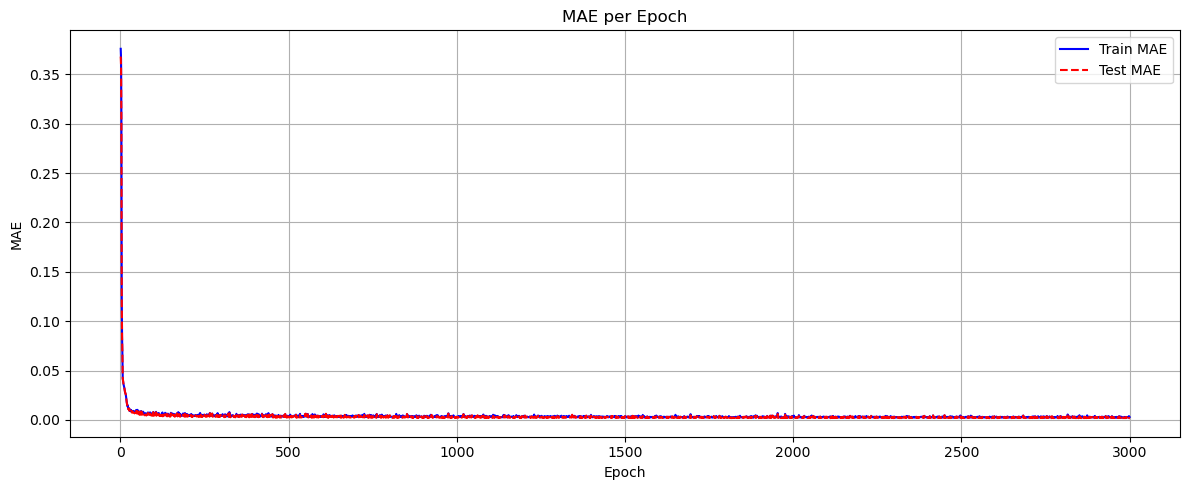

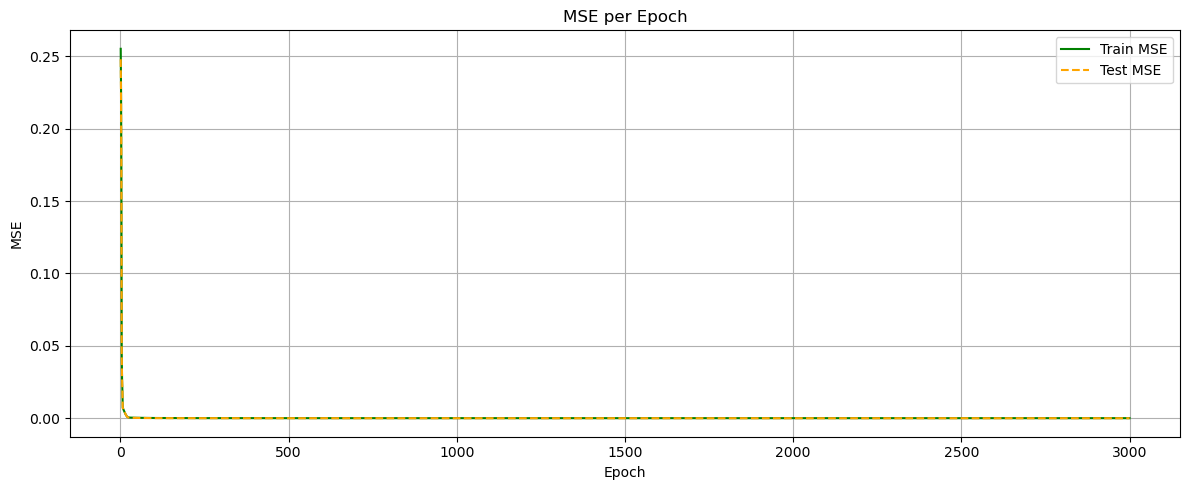

In [13]:
epochs = range(1, N_Epochs + 1)
train_mae_hist = [h[0] for h in train_history]
train_mse_hist = [h[1] for h in train_history]
test_mae_hist = [h[0] for h in test_history]
test_mse_hist = [h[1] for h in test_history]

plt.figure(figsize=(12, 5))
plt.plot(epochs, train_mae_hist, label="Train MAE", color="blue")
plt.plot(epochs, test_mae_hist, label="Test MAE", color="red", linestyle="--")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("MAE per Epoch")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(epochs, train_mse_hist, label="Train MSE", color="green")
plt.plot(epochs, test_mse_hist, label="Test MSE", color="orange", linestyle="--")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("MSE per Epoch")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Full test-set prediction vs ground truth

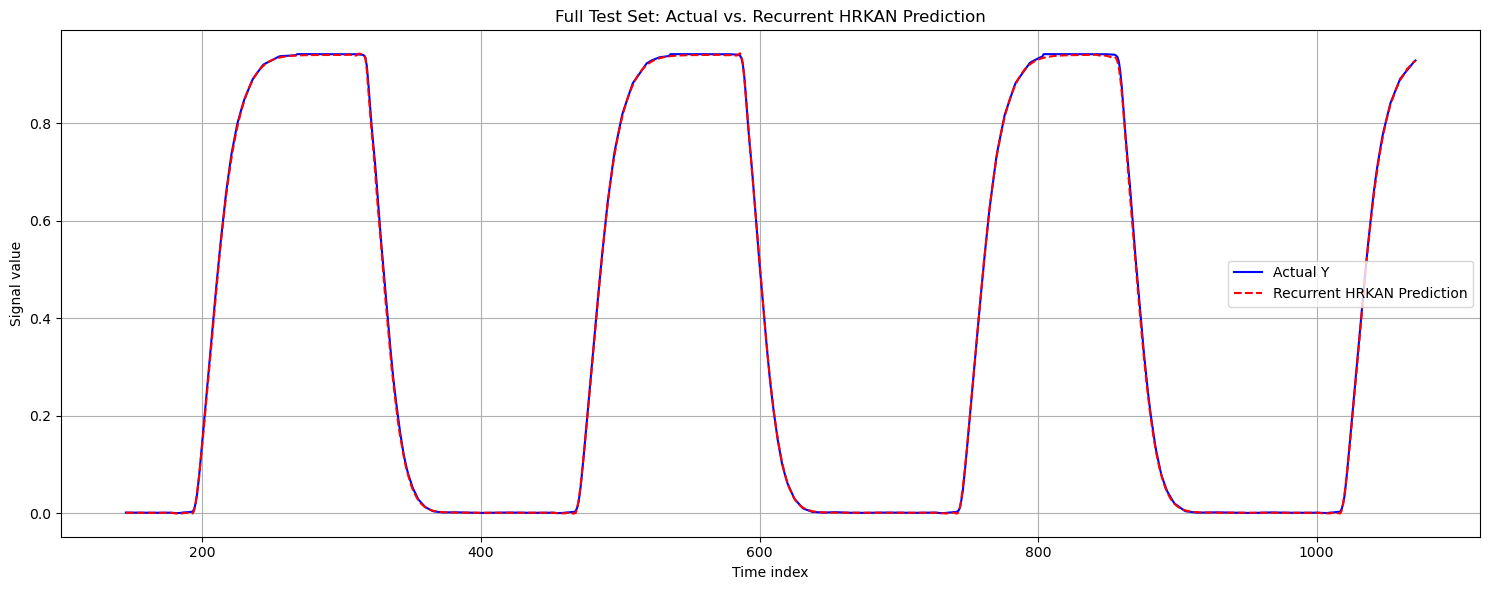

In [15]:
model.eval()
full_predicted_Y_test = np.full_like(Y_test, np.nan, dtype=np.float64)

with torch.no_grad():
    for idx in range(len(test_dataset)):
        x_win, _ = test_dataset[idx]
        x_win = x_win.unsqueeze(0).to(device)
        y_pred_win = model(x_win).cpu().squeeze(0).numpy()

        start_idx = idx + Context_Len
        end_idx = start_idx + Pred_Len
        if start_idx < len(Y_test):
            full_predicted_Y_test[start_idx:min(end_idx, len(Y_test))] = y_pred_win[:min(Pred_Len, len(Y_test) - start_idx)]

start_plot = 145
plt.figure(figsize=(15, 6))
plt.plot(np.arange(start_plot, len(Y_test)), Y_test[start_plot:], label="Actual Y", color="blue")
plt.plot(np.arange(start_plot, len(full_predicted_Y_test)), full_predicted_Y_test[start_plot:],
         label="Recurrent HRKAN Prediction", color="red", linestyle="--")
plt.xlabel("Time index")
plt.ylabel("Signal value")
plt.title("Full Test Set: Actual vs. Recurrent HRKAN Prediction")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()